# Week 8 - Dynamic Programming 1

# Part 1: Recap - OLS demand model
We estimate a linear demand model `demand = a*price + b*price_competitor + c` from the duopoly competition data.

In [1]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### load competition data and show some stats

In [15]:
results_dir = "results"
if not os.path.isdir(results_dir):
    results_dir = os.path.join("..", "..", "results")
if not os.path.isdir(results_dir):
    raise FileNotFoundError("Could not find the results folder")

file_selection = "duopoly_competition_details_1121.csv"  # Use a CSV filename here to load only that file.
if file_selection == "all":
    file_names = sorted(
        name for name in os.listdir(results_dir)
        if name.startswith("duopoly_competition_details") and name.endswith(".csv")
    )
else:
    file_names = [file_selection]

file_paths = [os.path.join(results_dir, name) for name in file_names]
if not file_paths:
    raise FileNotFoundError(f"No competition-details CSV files found in {results_dir!r}")

for file_path in file_paths:
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"CSV file not found: {file_path}")

df_comp_details = pd.concat(
    [pd.read_csv(file_path) for file_path in file_paths], ignore_index=True
)
df_comp_details.fillna(0, inplace=True)

df_comp_details['revenue'] = df_comp_details['price'] * df_comp_details['demand']

df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,revenue
0,32UkVJ,1,1,IndependentCoati,65.0,65.0,1,True,0.0,0.0,65.0
1,32UkVJ,1,2,IndependentCoati,65.0,65.7,0,True,0.0,0.0,0.0
2,32UkVJ,1,3,IndependentCoati,65.0,61.9,1,True,0.0,0.0,61.9


In [16]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

In [17]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()
dfx_rev.head(3)

,unique_selling_season_key,revenue
0,32UkVJ_1,3777.9
1,32UkVJ_10,3886.7
2,32UkVJ_100,4822.3


# Let us build our own demand model based on the competition data.

## => f(price, competitor_price) = demand

## idea:
- split selling_season into sub-intervals where we assume a constant demand model
    - e.g. **selling period [1,20]** assumed to have almost constant demand
- estimate the demand model per competition
- train on first 50 selling_seasons and evaluate on the last 50

36q8Dv


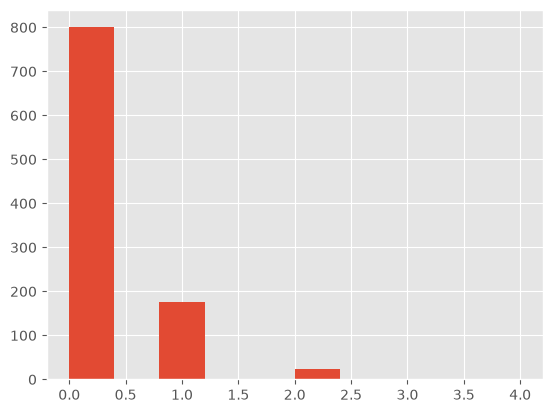

In [18]:
comp = df_comp_details.competition_id.unique()[1]
print(comp)

# filter on first competion_id
df = df_comp_details[df_comp_details.competition_id==comp ]
df = df[(df.price < 145) & (df.price_competitor > 0)]
# concentrate on selling period in [1,20]
df = df[df.selling_period <= 20 ]

df_train = df[df.selling_season<=50]
df_test = df[df.selling_season>50]

df_train.demand.hist()
plt.show()

## (a) fit OLS model

In [20]:
import statsmodels.api as sm
# https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html

y = df_train.demand
X = df_train[['price', 'price_competitor']] #, 'selling_period']]
X['intercept'] = 1

mod = sm.OLS(y, X)

res = mod.fit()

print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                 demand   R-squared:                       0.026
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     13.50
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.63e-06
Time:                        09:09:46   Log-Likelihood:                -677.05
No. Observations:                1000   AIC:                             1360.
Df Residuals:                     997   BIC:                             1375.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
price               -0.0107      0.002  

## (b) predict demand based on function for
- own price = 30
- competitor price = 50

In [21]:
mod.predict(res.params, [30, 50, 1])

np.float64(0.5329192616391796)

## (c) simulate demand, our prices in [1,100] and competitor_price = 50

In [22]:
def est_demand(price, comp_price, para = res.params):
    demand = mod.predict(para, [price, comp_price, 1])
    demand = max(0,demand)
    return demand


df_sim = pd.DataFrame(columns = ['price','demand','rev'])
for p in np.arange(1,100,1):
    demand = est_demand(price=p, comp_price=50)
    rev = p * demand
    df_sim.loc[len(df_sim)] = [p,demand,rev]
    
df_sim.head()

,price,demand,rev
0,1.0,0.843262,0.843262
1,2.0,0.832561,1.665121
2,3.0,0.821859,2.465577
3,4.0,0.811158,3.244630
4,5.0,0.800456,4.002280


#### plot demand and revenue curve

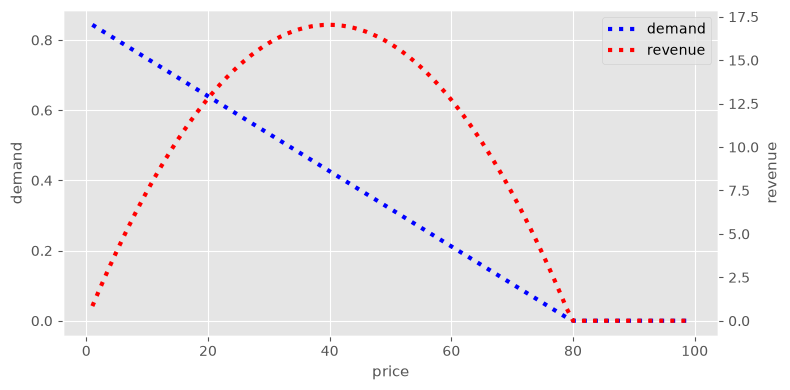

In [23]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(df_sim['price'], df_sim['demand'], color='b', 
        linestyle='dotted', linewidth=3, label='demand')

ax_2 = ax.twinx()
ax_2.grid(False)
ax_2.plot(df_sim['price'], df_sim['rev'], color='r', 
        linestyle='dotted', linewidth=3, label='revenue')

ax_2.tick_params(axis="both", labelsize=10)
ax.tick_params(axis="both", labelsize=10)

# legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_2.get_legend_handles_labels()
ax_2.legend(lines + lines2, labels + labels2, loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)
ax_2.set_ylabel("revenue" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

## (d) compute estimated demand in computation details

In [24]:
df_eval = df_test[['unique_selling_season_key','selling_season','selling_period','price_competitor', 'price', 'demand']]

df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand
15000,36q8Dv_51,51,1,13.2,52.0,0
15001,36q8Dv_51,51,2,13.2,27.5,0
15002,36q8Dv_51,51,3,13.2,22.0,0
15003,36q8Dv_51,51,4,13.2,24.0,0
15004,36q8Dv_51,51,5,13.2,22.0,1


In [25]:
# estimate demand
df_eval['est_demand'] = df_eval.apply(lambda r:
            est_demand(price=r.price, comp_price=r.price_competitor),
            axis=1)

# compute error metrics
df_eval['est_error'] = df_eval['est_demand'] - df_eval['demand']
df_eval['abs_est_error'] = df_eval['est_error'].abs()

df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand,est_demand,est_error,abs_est_error
15000,36q8Dv_51,51,1,13.2,52.0,0,0.000000,0.000000,0.000000
15001,36q8Dv_51,51,2,13.2,27.5,0,0.154587,0.154587,0.154587
15002,36q8Dv_51,51,3,13.2,22.0,0,0.213445,0.213445,0.213445
15003,36q8Dv_51,51,4,13.2,24.0,0,0.192042,0.192042,0.192042
15004,36q8Dv_51,51,5,13.2,22.0,1,0.213445,-0.786555,0.786555


In [26]:
df_eval[['demand', 'est_demand', 'est_error', 'abs_est_error']].describe()

,demand,est_demand,est_error,abs_est_error
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.254000,0.241151,-0.012849,0.376264
std,0.505707,0.068430,0.496376,0.323787
min,0.000000,0.000000,-2.750229,0.000000
25%,0.000000,0.216259,0.000000,0.225553
50%,0.000000,0.249771,0.225553,0.252585
75%,0.000000,0.273988,0.261879,0.338246
max,3.000000,0.370856,0.360155,2.750229


### plot the actual demand vs. estimated demand for one test selling season

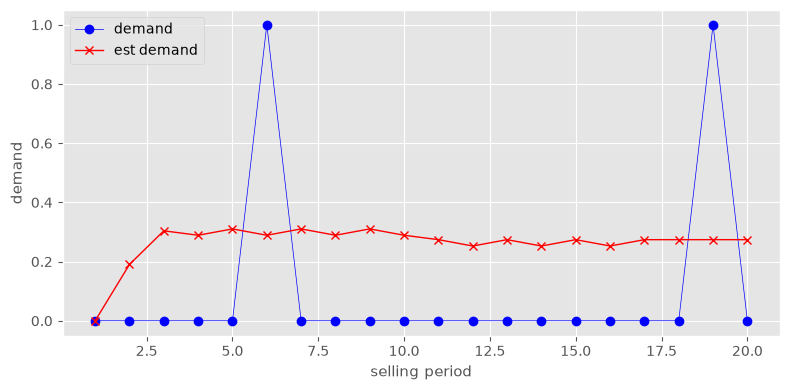

In [27]:
dfe = df_eval[df_eval.selling_season==60]

fig, ax = plt.subplots(figsize=(8,4))

ax.plot(dfe['selling_period'], dfe['demand'], color='b', 
        linestyle='-', marker='o', linewidth=0.5, markersize=6, label='demand')

ax.plot(dfe['selling_period'], dfe['est_demand'], color='r', 
        linestyle='-', marker='x', linewidth=1, markersize=6, label='est demand')

ax.legend( loc=0)

ax.set_xlabel('selling period', size=11)
ax.set_ylabel("demand" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

# Part 2: Dynamic programming
From here on we work with a **fixed** linear demand model. Its parameters come from an earlier OLS fit
(**price -0.0564, competitor price 0.0133, intercept 3.676**). 

The fit in Part 1 above gives different numbers -
you can plug `list(res.params)` into every `para=` argument below and rerun the dynamic program with your own model.

Note: `est_demand` is redefined below with these fixed parameters.

In [29]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
from tqdm import tqdm

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### given demand function

In [30]:
def est_demand(price, 
               comp_price, 
               para = [-0.0564, 0.0133, 3.676]):
    """
    parameter from OLS (last week):
    price              -0.056444
    price_competitor    0.013317
    intercept           3.675965
    """
    demand = para[0]*price + para[1]*comp_price + para[2]
    demand = max(0,demand)
    return round(demand,3)

## get the revenue maximizing price by brute force for loop with prices 1..100

In [31]:
revenues = []
demands = []
best_rev = 0
best_p = 0
for p in np.arange(1,100,0.5):
    d = est_demand(price=p, 
               comp_price=50, 
               para = [-0.0564, 0.0133, 3.676])
    
    if d*p > best_rev:
        best_rev = d*p
        best_p = p
        
    demands.append(d)
    revenues.append(d*p)
        
print("best revenue: %.2f" % best_rev)
print("best price: %.2f" % best_p)

best revenue: 83.55
best price: 38.50


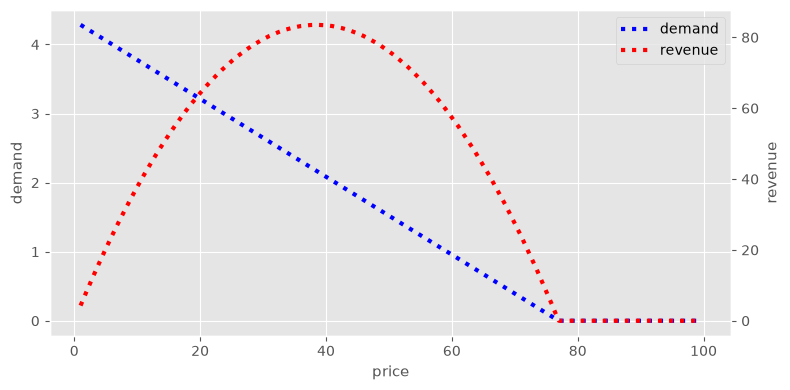

In [32]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(np.arange(1,100,0.5), demands, color='b', 
        linestyle='dotted', linewidth=3, label='demand')

ax_2 = ax.twinx()
ax_2.grid(False)
ax_2.plot(np.arange(1,100,0.5), revenues, color='r', 
        linestyle='dotted', linewidth=3, label='revenue')

ax_2.tick_params(axis="both", labelsize=10)
ax.tick_params(axis="both", labelsize=10)

# legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_2.get_legend_handles_labels()
ax_2.legend(lines + lines2, labels + labels2, loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)
ax_2.set_ylabel("revenue" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

## Define the function opt_price(.) to analytically compute the optimal price.

In [33]:
def opt_price(comp_price, 
              para = [-0.0564, 0.0133, 3.676]):
    """
    parameter from OLS (last week):
    price              -0.056444
    price_competitor    0.013317
    intercept           3.675965
    """
    opt_price = (-para[1]*comp_price - para[2]) / (2*para[0])
    # putting the price in feasible bundaries of [1,100]
    opt_price = max(1,min(100,opt_price))
    return round(opt_price,2)

In [34]:
opt_price(comp_price=50, para = [-0.0564, 0.0133, 3.676])

38.48

## Use opt_price(comp_price, para) to optimize the revenue in every time period. What is the total revenue you expect to make?
- capacity = 20
- consider 10 time periods for selling
- OLS parameter for price, competitor_price and intercept are [-0.0564, 0.0133, 3.676]
- assume constant competitor price of 50

In [35]:
capacity = 20
T_max = 10
rev = 0

for t in range(1, T_max+1):
    if capacity>0:
        p_opt = opt_price(comp_price=50)
        demand = est_demand(price=p_opt, comp_price=50)
        demand = min(capacity,demand)
        rev += p_opt * demand
        capacity -= demand
    else:
        p_opt = np.nan
        demand = np.nan
    print("t=%d, price=%.1f, demand=%.1f, revenue=%.2f, remaining_capacity=%.1f" \
          % (t,p_opt,demand,rev,capacity))

rev_myopic = rev

t=1, price=38.5, demand=2.2, revenue=83.54, remaining_capacity=17.8
t=2, price=38.5, demand=2.2, revenue=167.08, remaining_capacity=15.7
t=3, price=38.5, demand=2.2, revenue=250.62, remaining_capacity=13.5
t=4, price=38.5, demand=2.2, revenue=334.16, remaining_capacity=11.3
t=5, price=38.5, demand=2.2, revenue=417.70, remaining_capacity=9.1
t=6, price=38.5, demand=2.2, revenue=501.24, remaining_capacity=7.0
t=7, price=38.5, demand=2.2, revenue=584.78, remaining_capacity=4.8
t=8, price=38.5, demand=2.2, revenue=668.32, remaining_capacity=2.6
t=9, price=38.5, demand=2.2, revenue=751.86, remaining_capacity=0.5
t=10, price=38.5, demand=0.5, revenue=769.60, remaining_capacity=0.0


### What happens when we use a flat price of 45 in the above example?

In [36]:
capacity = 20
T_max = 10
rev = 0
p = 45

for t in range(1, T_max+1):
    if capacity>0:
        demand = est_demand(price=p, comp_price=50)
        demand = min(capacity,demand)
        rev += p * demand
        capacity -= demand
    else:
        p = np.nan
        demand = np.nan
    print("t=%d, price=%.1f, demand=%.1f, revenue=%.2f, remaining_capacity=%.1f" \
          % (t,p,demand,rev,capacity))

rev_flat = rev

t=1, price=45.0, demand=1.8, revenue=81.13, remaining_capacity=18.2
t=2, price=45.0, demand=1.8, revenue=162.27, remaining_capacity=16.4
t=3, price=45.0, demand=1.8, revenue=243.40, remaining_capacity=14.6
t=4, price=45.0, demand=1.8, revenue=324.54, remaining_capacity=12.8
t=5, price=45.0, demand=1.8, revenue=405.67, remaining_capacity=11.0
t=6, price=45.0, demand=1.8, revenue=486.81, remaining_capacity=9.2
t=7, price=45.0, demand=1.8, revenue=567.94, remaining_capacity=7.4
t=8, price=45.0, demand=1.8, revenue=649.08, remaining_capacity=5.6
t=9, price=45.0, demand=1.8, revenue=730.21, remaining_capacity=3.8
t=10, price=45.0, demand=1.8, revenue=811.35, remaining_capacity=2.0


# => An optimal strategie consider also the future possible revenue not just the revenue in the current period.

## Define a function get_best_price_target_demand( target_demand, comp_price, para ) which return the price which results in the closest demand realization to the given target.

In [37]:
def get_best_price_target_demand(target_demand, 
                                 comp_price=50,
                                 para = [-0.0564, 0.0133, 3.676]):
    """
    given target demand, compute the best price to generate 
    demand as close as possible to the target_demand
    
    return: tupel of best price and the corresponding demand
    """
    delta_demand = 1000
    best_p = 0
    best_realistic_demand = 0
    # loop over all feasible prices
    for p in np.arange(1,100,0.5):
        d = est_demand(p, comp_price,para)
        # check of new price brings us closer to our target demand
        if abs(target_demand-d) < delta_demand :
            delta_demand = abs(target_demand-d)
            best_p = p
            best_realistic_demand = d
            
    return best_p, round(best_realistic_demand)

In [38]:
get_best_price_target_demand(target_demand=3)

(np.float64(24.0), 3)

# Fill the value function matrix
- fill a dataframe df_V = pd.DataFrame(columns=['t','free_cap','V_t','price_t','demand_t'])
    - t = time periods to sell 
    - V_t = value of having free_cap remaining capacity at time period t, given we use price_t 
    - price_t = price to use in period t
    - demand_t = resulting demand in period t given price_t
- fill this dataframe matrix for all t=0,...,100 and free_cap=80,...,0
- V_0(x) = 0 for all free_capacity level x
- use OLS parameter for price, competitor_price and intercept are [-0.0564, 0.0133, 3.676]
    - assume you can at most create a demand of 5 per time period
    - assume competitor price of 50

In [39]:
T_MAX   = 100   # selling periods (t counts DOWN: t = remaining periods)
CAP_MAX = 80    # capacity levels 0..80
D_MAX   = 5     # at most a demand of 5 per period

df_V = pd.DataFrame(columns=['t','free_cap','V_t','price_t','demand_t'])

# fill the value function dataframe at the boundary condition t=0 
# at all capacity levels with value 0
for free_cap in range(CAP_MAX+1):
    df_V.loc[len(df_V)] = [0, free_cap, 0, 0, 0]
    
for t in tqdm(range(1,T_MAX+1)):
    for free_cap in range(CAP_MAX+1):
        # d = 0 .. min(D_MAX, free_cap) INCLUDING free_cap, otherwise we never sell the last unit
        for demand in range(0, min(D_MAX, free_cap) + 1):
            best_price, best_demand = get_best_price_target_demand(target_demand=demand)
            V_tmin1 = df_V[(df_V.t==t-1) & (df_V.free_cap==(free_cap-best_demand))].V_t.max()
            V_t = best_price * best_demand + V_tmin1
            df_V.loc[len(df_V)] = [t, free_cap, V_t, best_price, best_demand]

# value function V[t, x] = best value over all actions d  (used in the cells below)
V = df_V.groupby(['t', 'free_cap']).V_t.max().unstack().values

df_V

100%|██████████| 100/100 [03:44<00:00,  2.24s/it]


,t,free_cap,V_t,price_t,demand_t
0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0
2,0.0,2.0,0.0,0.0,0.0
3,0.0,3.0,0.0,0.0,0.0
4,0.0,4.0,0.0,0.0,0.0
...,...,...,...,...,...
47176,100.0,80.0,4720.0,59.0,1.0
47177,100.0,80.0,4685.0,41.5,2.0
47178,100.0,80.0,4615.0,24.0,3.0
47179,100.0,80.0,4508.0,6.0,4.0


## Define a function best_action(t, free_cap) which uses our dtaframe df_V to find the best price action at given time period and remaining capacity level
- at given **t**
- at remaining capacity **x**
- chose price which gives highest **V_t(x)**

In [134]:
def best_action(t, free_cap):
    df_aux = df_V[ df_V.t== t ]
    df_aux = df_aux[ df_aux.free_cap==free_cap ]
    df_aux = df_aux[ df_aux.V_t == df_aux.V_t.max() ]
    # if multiple prices have the same value function, take the highest price
    if len(df_aux)>1 :
        df_aux = df_aux[ df_aux.price_t == df_aux.price_t.max() ]
    print("best action at time t = %d and free capacity level = %d:" % (t,free_cap))
    print("\t price = %.1f" % df_aux.price_t.values[0])
    print("\t expected demand = %.1f" % df_aux.demand_t.values[0])
    print("\t value function = %.1f" % df_aux.V_t.values[0])
    # display(df_aux)
    
    return df_aux.price_t.values[0]


best_action(t=10, free_cap=30)

best action at time t = 10 and free capacity level = 30:
	 price = 41.5
	 expected demand = 2.0
	 value function = 830.0


np.float64(41.5)

## Follow the DP policy and compare it with the myopic and the flat price
- capacity = 20, 10 selling periods, competitor price 50 
- in every period look up the best action in our value function table

In [135]:
def policy(t, free_cap):
    """best (price, demand, value) at t periods left and free_cap capacity 
        - without discounting, selling a unit now or in a later period has the same value
        - among equally good actions we prefer the one that earns the most NOW 
    """
    df_aux = df_V[(df_V.t == t) & (df_V.free_cap == free_cap)]
    df_aux = df_aux[df_aux.V_t == df_aux.V_t.max()]
    now_rev = df_aux.price_t * df_aux.demand_t
    df_aux = df_aux[now_rev == now_rev.max()]
    return df_aux.price_t.values[0], int(df_aux.demand_t.values[0]), df_aux.V_t.values[0]

capacity = 20
T_max = 10
rev = 0
dp_prices = []
for t in range(T_max, 0, -1):
    p, d, v = policy(t, capacity)
    rev += p * d
    capacity -= d
    dp_prices.append(p)
    print("t=%2d, price=%.1f, demand=%d, revenue=%.2f, remaining_capacity=%d" % (t, p, d, rev, capacity))

print("\nDP plan value V_10(20) = %.1f" % V[10, 20])

t=10, price=41.5, demand=2, revenue=83.00, remaining_capacity=18
t= 9, price=41.5, demand=2, revenue=166.00, remaining_capacity=16
t= 8, price=41.5, demand=2, revenue=249.00, remaining_capacity=14
t= 7, price=41.5, demand=2, revenue=332.00, remaining_capacity=12
t= 6, price=41.5, demand=2, revenue=415.00, remaining_capacity=10
t= 5, price=41.5, demand=2, revenue=498.00, remaining_capacity=8
t= 4, price=41.5, demand=2, revenue=581.00, remaining_capacity=6
t= 3, price=41.5, demand=2, revenue=664.00, remaining_capacity=4
t= 2, price=41.5, demand=2, revenue=747.00, remaining_capacity=2
t= 1, price=41.5, demand=2, revenue=830.00, remaining_capacity=0

DP plan value V_10(20) = 830.0


### Summary: how much is it worth to look into the future?

In [136]:
results = pd.Series({'myopic price 38.5': rev_myopic,
                     'flat price 45': rev_flat,
                     'dynamic programming': V[10, 20]})
results.round(1)

myopic price 38.5      769.6
flat price 45          811.3
dynamic programming    830.0
dtype: float64